### Workshop - 1 : Adding Sunglasses to Your Passport Photo Using OpenCV

### Register No : 212225230239

### Name : Sai Praveen C

In [91]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

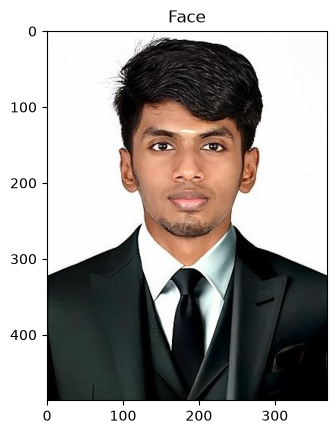

In [92]:
faceImage = cv2.imread('sai2.JPeG')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [93]:
faceImage.shape

(487, 369, 3)

In [94]:
faceImage.shape

(487, 369, 3)

Text(0.5, 1.0, 'glassPNG')

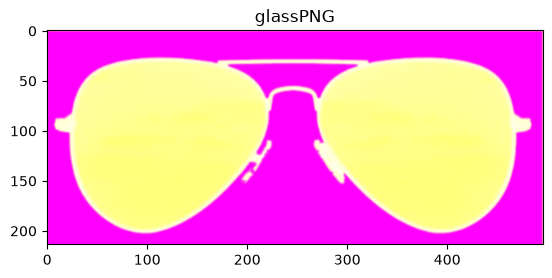

In [95]:
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [96]:
glassPNG = cv2.resize(glassPNG,(152,48))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(48, 152, 4)


In [97]:
glassBGR = glassPNG[:, :, 0:3].copy()
cyan_bg = (glassBGR[:, :, 0] > 150) & (glassBGR[:, :, 1] > 150) & (glassBGR[:, :, 2] < 120)
glassMask1 = np.where(cyan_bg, 0, 255).astype(np.uint8)
height, width = glassBGR.shape[:2]
gradient = np.linspace(0, 1, height)[:, None]
top_color = np.array([120, 55, 30], dtype=np.float32)    
bottom_color = np.array([190, 115, 60], dtype=np.float32)  
gradient_blue = (1 - gradient) * top_color + gradient * bottom_color
gradient_blue = np.tile(gradient_blue[:, None, :], (1, width, 1)).astype(np.uint8)
lens_area = (glassBGR[:, :, 2] > 150) & (glassMask1 == 255)
glassBGR[lens_area] = gradient_blue[lens_area]
frame_area = (glassBGR[:, :, 2] <= 150) & (glassMask1 == 255)
glassBGR[frame_area] = [50, 50, 50]

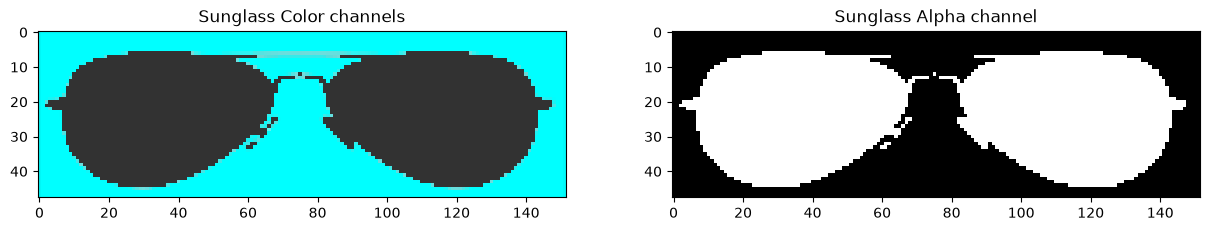

In [98]:
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

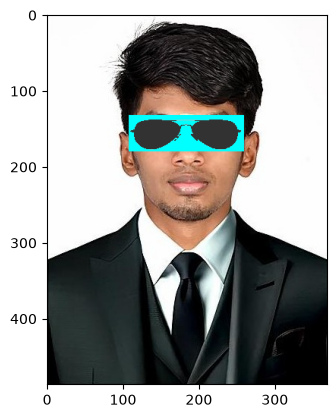

In [99]:
faceWithGlassesNaive = faceImage.copy()
faceWithGlassesNaive[132:180,108:260]=glassBGR
plt.imshow(faceWithGlassesNaive[...,::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

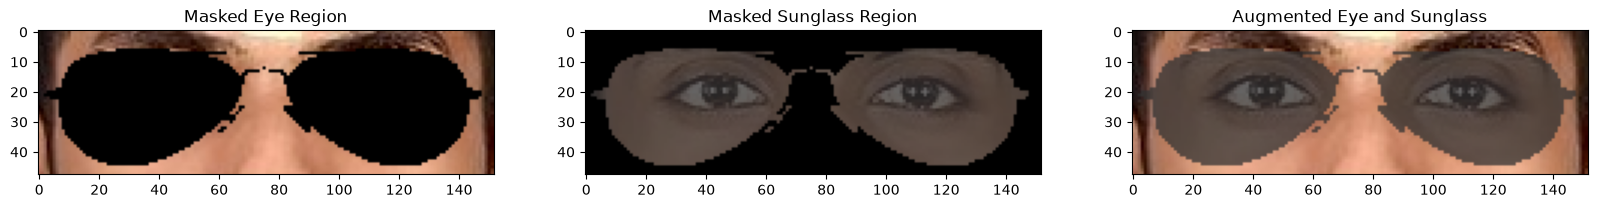

In [100]:
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = np.uint8(glassMask / 255)
faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[132:180, 108:260]
tinted_glasses = cv2.addWeighted(glassBGR, 0.75, eyeROI, 0.25, 0)
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))
maskedGlass = cv2.multiply(tinted_glasses, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)
plt.figure(figsize=[20, 20])
plt.subplot(131); plt.imshow(maskedEye[..., ::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[..., ::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[..., ::-1]); plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

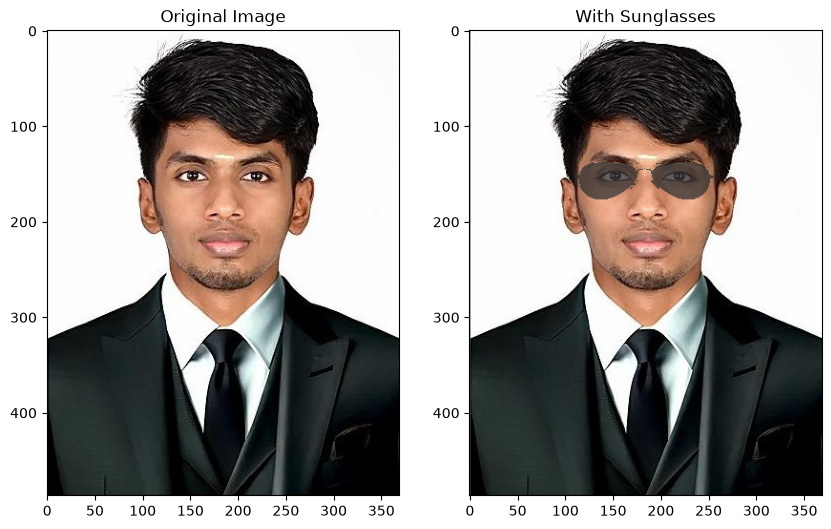

In [103]:
faceWithGlassesArithmetic[132:180, 108:260] = eyeRoiFinal
plt.figure(figsize=[10, 10])
plt.subplot(121); plt.imshow(faceImage[:, :, ::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:, :, ::-1]); plt.title("With Sunglasses")